<h1>FITCOMP 2026</h1>
<h2>Identity and Data Exploitation [Digital Security]</h2>
==============================================================================================<br><br>
Team Members:<br>
- Naila Dzulfa<br>
- Azhari Rahma Putri<br>
- Muhammad Naufal Syahputra<br>
Institution: Institut Teknologi Sepuluh Nopember<br>

****
<p>here, we present our solution for the FITCOMP 2026 competition, focusing on Identity and Data Exploitation in the realm of Digital Security. In this case, we have to analyst a dataset containing URLs and their corresponding labels (malicious or benign). Our goal is to develop a machine learning model that can accurately classify URLs based on their features, helping to identify potential threats and enhance cybersecurity measures.</p>

In this case, we experimented to find the 'best' model in terms of accuracy, F1-score, and recall. We tested several commonly used machine learning models, such as Logistic Regression, Support Vector Machine (SVM), K-Nearest Neighbors (KNN), Random Forest, Gradient Boosting, and XGBoost, as well as utilizing a Stacking Ensemble. Additionally, we also tried Deep Learning models specifically a Tabular Neural Network and a Sequential Dense Layer network for comparison. After conducting the evaluation, we found that the XGBoost model delivered the best results, providing high accuracy, a strong F1-score, and the most efficient runtime in classifying URLs as malicious or benign.
***

**Execution Steps:**
1. Data Loading & Inspection
2. Data Preprocessing & Cleaning
3. Feature Engineering
4. Train-Test Split & Preparation
5. Model Selection & Training
6. Model Evaluation & Comparison
7. Final Model Selection & Submission
------------------------------

1. Data Loading & Inspection

Here, we load the dataset and perform an initial inspection to understand its structure, identify any missing values, and check for duplicates. This step is crucial for ensuring that our data is clean and ready for further analysis and modeling.

***Data Loading & Inspection Steps:***
1. Import necessary libraries
2. Load Dataset & Display Basic Information
3. Missing Value Check
4. Data Duplication Check

    1.1 Import Library

In [2]:
import pandas as pd
import numpy as np
import time
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import StackingClassifier

from sklearn.feature_selection import SelectFromModel

from boruta import BorutaPy

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from pytorch_tabnet.tab_model import TabNetClassifier
import torch.optim as optim

from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

I0000 00:00:1781617089.523633    8249 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
np.random.seed(42)
tf.random.set_seed(42)

    1.2 Load Dataset

In [3]:
data = pd.read_csv('Dataset.csv')
data.head()

,Type,url_length,number_of_dots_in_url,having_repeated_digits_in_url,number_of_digits_in_url,number_of_special_char_in_url,number_of_hyphens_in_url,number_of_underline_in_url,number_of_slash_in_url,number_of_questionmark_in_url,...,having_digits_in_subdomain,number_of_digits_in_subdomain,having_repeated_digits_in_subdomain,having_path,path_length,having_query,having_fragment,having_anchor,entropy_of_url,entropy_of_domain
0,0,37,2,0,0,8,0,0,5,0,...,0,0,1,0,3,0,0,0,4.010412,2.751629
1,1,70,5,0,0,12,0,0,6,0,...,0,0,1,0,4,0,0,0,4.089470,3.532573
2,0,42,2,0,6,8,0,0,3,1,...,0,0,1,0,1,1,0,0,4.386016,3.344698
3,0,46,2,0,0,7,0,0,4,0,...,0,0,1,0,2,0,0,0,4.221947,3.189898
4,0,51,3,0,0,9,0,0,5,0,...,0,0,1,0,3,0,0,0,4.103538,2.952820


In [4]:
data.shape

(247950, 42)

In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247950 entries, 0 to 247949
Data columns (total 42 columns):
 #   Column                                     Non-Null Count   Dtype  
---  ------                                     --------------   -----  
 0   Type                                       247950 non-null  int64  
 1   url_length                                 247950 non-null  int64  
 2   number_of_dots_in_url                      247950 non-null  int64  
 3   having_repeated_digits_in_url              247950 non-null  int64  
 4   number_of_digits_in_url                    247950 non-null  int64  
 5   number_of_special_char_in_url              247950 non-null  int64  
 6   number_of_hyphens_in_url                   247950 non-null  int64  
 7   number_of_underline_in_url                 247950 non-null  int64  
 8   number_of_slash_in_url                     247950 non-null  int64  
 9   number_of_questionmark_in_url              247950 non-null  int64  
 10  number_o

    1.3 Data Missing Check

In [6]:
data.isna().sum()

Type                                         0
url_length                                   0
number_of_dots_in_url                        0
having_repeated_digits_in_url                0
number_of_digits_in_url                      0
number_of_special_char_in_url                0
number_of_hyphens_in_url                     0
number_of_underline_in_url                   0
number_of_slash_in_url                       0
number_of_questionmark_in_url                0
number_of_equal_in_url                       0
number_of_at_in_url                          0
number_of_dollar_in_url                      0
number_of_exclamation_in_url                 0
number_of_hashtag_in_url                     0
number_of_percent_in_url                     0
domain_length                                0
number_of_dots_in_domain                     0
number_of_hyphens_in_domain                  0
having_special_characters_in_domain          0
number_of_special_characters_in_domain       0
having_digits

    1.4 Data Duplication Check

In [7]:
data.duplicated().sum()

np.int64(118172)

***

2. Data Preprocessing & Cleaning

Data preprocessing and cleaning are essential steps to ensure that our dataset is in the best possible shape for modeling. Given the nature of cybersecurity datasets, which often contain massive redundancies from repeated threat signatures, rigorous preprocessing is critical to prevent data leakage and ensure the model learns generalized patterns rather than memorized noise. 

***Our preprocessing pipeline involves:***
1. Cleaning Duplicates (make new variable for clean duplicates)
2. Zero-Variance Feature Removal & Data Sanitization

Proper execution of these steps not only significantly improves the predictive performance of our models but also highly optimizes the training efficiency.

    2.1 Cleaning Duplicates (make new variable for duplicates)

In [8]:
clean_data= data.drop_duplicates()
clean_data.duplicated().sum()

np.int64(0)

In [9]:
clean_data.shape

(129778, 42)

In [10]:
clean_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 129778 entries, 0 to 247939
Data columns (total 42 columns):
 #   Column                                     Non-Null Count   Dtype  
---  ------                                     --------------   -----  
 0   Type                                       129778 non-null  int64  
 1   url_length                                 129778 non-null  int64  
 2   number_of_dots_in_url                      129778 non-null  int64  
 3   having_repeated_digits_in_url              129778 non-null  int64  
 4   number_of_digits_in_url                    129778 non-null  int64  
 5   number_of_special_char_in_url              129778 non-null  int64  
 6   number_of_hyphens_in_url                   129778 non-null  int64  
 7   number_of_underline_in_url                 129778 non-null  int64  
 8   number_of_slash_in_url                     129778 non-null  int64  
 9   number_of_questionmark_in_url              129778 non-null  int64  
 10  number_of_equ

    2.2 Zero-Variance Feature Removal & Data Sanitization for Tabular Neural Networks

In [11]:
constant_cols = [col for col in clean_data.columns if clean_data[col].nunique() <= 1]

data_dl = clean_data.drop(columns=constant_cols).copy()
data_dl = data_dl.replace([np.inf, -np.inf], np.nan)
data_dl = data_dl.dropna()

print(f"Data shape for ML (clean_data): {clean_data.shape}")
print(f"Data shape for DL (data_dl)   : {data_dl.shape}")

Data shape for ML (clean_data): (129778, 42)
Data shape for DL (data_dl)   : (129778, 35)


In [12]:
print(data_dl['Type'].value_counts())

Type
0    66755
1    63023
Name: count, dtype: int64


***

3. Feature Engineering

Feature engineering and selection are critical steps in the machine learning pipeline, especially for cybersecurity datasets where raw features may contain significant noise and redundancies. In this phase, our goal is to amplify the predictive signal while maintaining computational efficiency.

***We implement a dual-track approach tailored for our two modeling paradigms:***

1. **Track 1: Traditional Machine Learning (e.g., XGBoost, LightGBM)**
   - We focus on creating **new synthetic features** based on domain knowledge. By extracting metrics such as the ratio of domain to URL length, digit density, and the frequency of suspicious characters, we explicitly highlight structural anomalies often associated with phishing and malicious URLs. These engineered features are directly fed into tree-based models, which naturally handle feature interactions and splits.

2. **Track 2: Deep Learning Models (e.g., TabNet, Keras Sequential DNN)**
   - Neural networks are highly sensitive to noisy and uninformative inputs. Instead of manually engineering new columns, our Deep Learning track relies on a rigorous **Hybrid Feature Selection** pipeline. We utilize **L1 Regularization (Lasso)** to drop linear noise and the **Boruta Algorithm** to validate non-linear feature importance. Finally, the highly curated feature subset is cast into a lightweight 32-bit floating-point format (`float32`) to ensure maximum memory efficiency during tensor operations.

    3.1 Feature Engineering for Machine Learning

        3.1.1 Threat Pattern Aggregation

In [13]:
def create_new_features(data):
    df_feat = data.copy()
    
    # Feature 1: Ratio of domain length to total URL length
    df_feat['ratio_domain_url'] = df_feat['domain_length'] / (df_feat['url_length'] + 1e-5)
    
    # Feature 2: Ratio of path length to total URL length
    df_feat['ratio_path_url'] = df_feat['path_length'] / (df_feat['url_length'] + 1e-5)
    
    # Feature 3: Digit density in the URL
    df_feat['digit_density_url'] = df_feat['number_of_digits_in_url'] / (df_feat['url_length'] + 1e-5)
    
    # Feature 4: Special character density in the domain
    df_feat['special_char_density_domain'] = (
        df_feat['number_of_special_characters_in_domain'] / (df_feat['domain_length'] + 1e-5)
    )
    
    # Feature 5: Total count of suspicious symbols
    suspicious_cols = [
        'number_of_dollar_in_url',
        'number_of_exclamation_in_url',
        'number_of_hashtag_in_url',
        'number_of_percent_in_url',
        'number_of_at_in_url'
    ]
    df_feat['total_suspicious_chars'] = df_feat[suspicious_cols].sum(axis=1)
    
    return df_feat

# Use clean_data as base features (excluding target column)
X = clean_data.drop(columns=['Type']).copy()

X_engineered = create_new_features(X)
print(f"Number of original columns: {X.shape[1]}")
print(f"Number of columns after Feature Engineering: {X_engineered.shape[1]}")

Number of original columns: 41
Number of columns after Feature Engineering: 46


In [14]:
X_engineered.head()

,url_length,number_of_dots_in_url,having_repeated_digits_in_url,number_of_digits_in_url,number_of_special_char_in_url,number_of_hyphens_in_url,number_of_underline_in_url,number_of_slash_in_url,number_of_questionmark_in_url,number_of_equal_in_url,...,having_query,having_fragment,having_anchor,entropy_of_url,entropy_of_domain,ratio_domain_url,ratio_path_url,digit_density_url,special_char_density_domain,total_suspicious_chars
0,37,2,0,0,8,0,0,5,0,0,...,0,0,0,4.010412,2.751629,0.324324,0.081081,0.000000,0.0,0
1,70,5,0,0,12,0,0,6,0,0,...,0,0,0,4.089470,3.532573,0.371429,0.057143,0.000000,0.0,0
2,42,2,0,6,8,0,0,3,1,1,...,1,0,0,4.386016,3.344698,0.500000,0.023810,0.142857,0.0,0
3,46,2,0,0,7,0,0,4,0,0,...,0,0,0,4.221947,3.189898,0.326087,0.043478,0.000000,0.0,0
4,51,3,0,0,9,0,0,5,0,0,...,0,0,0,4.103538,2.952820,0.313725,0.058824,0.000000,0.0,0


***

4. Train-Test Split & Preparation

Train-test split is a fundamental step in the machine learning workflow, allowing us to evaluate our model's performance on unseen data. In this phase, we divide our dataset into a training set, which is used to train the model, and a test set, which is used to evaluate its performance. This step is crucial for assessing how well our model generalizes to new data and helps prevent overfitting.
***Train-Test Split & Preparation Steps:***

To accommodate our dual-track modeling approach while strictly preventing data leakage, we execute the following sequence:

1. **Stratified Dual-Track Splitting:** We perform an 80:20 split separately for the Machine Learning dataset (containing engineered features) and the Deep Learning dataset (cleaned from constant/zero-variance columns). We utilize a stratified approach (`stratify=y`) across both tracks to perfectly preserve the class distribution of malicious vs. normal URLs in the training and testing sets.
2. **Independent Feature Scaling:** We apply `StandardScaler` to normalize the numerical ranges. Crucially, we isolate this process by using separate scalers for the ML and DL tracks to prevent mean/variance override. The scalers are fitted *only* on the training data, and the transformation is then applied to the test data to simulate real-world unseen inputs.
3. **Training-Set Feature Selection (DL Track):** As mentioned in the Feature Engineering section, the L1 + Boruta Hybrid Selection is executed *strictly* on the Deep Learning training set (`X_train_dl_scaled`). The test set is subsequently sliced to match only these validated features.
4. **Tensor Type Casting:** As a final preparatory step for the neural networks, the Deep Learning arrays are cast into 32-bit floating-point format (`np.float32`). This drastically improves computational stability and memory efficiency during PyTorch (TabNet) and Keras training phases.

    4.1 Machine Learning

        4.1.1 Train-Test Split for Machine Learning

In [15]:
X = X_engineered.drop(columns=['Type'], errors='ignore')
y = clean_data.loc[X_engineered.index, 'Type']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

        4.1.2 Data Scaling for Machine Learning

In [16]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

    4.2 Deep Learning

        4.2.1 Train-Test Split for Deep Learning

In [17]:
X_dl = data_dl.drop(columns=['Type']).copy()
y_dl = data_dl['Type'].copy()

X_dl_train, X_dl_test, y_dl_train, y_dl_test = train_test_split(
    X_dl, y_dl, test_size=0.2, random_state=42, stratify=y_dl
)

        4.2.2 Data Scaling for Deep Learning

In [18]:
feature_names_dl = X_dl_train.columns.tolist()
scaler_dl = StandardScaler()

X_train_dl_scaled = scaler_dl.fit_transform(X_dl_train)
X_test_dl_scaled = scaler_dl.transform(X_dl_test)

X_train_dl_df = pd.DataFrame(X_train_dl_scaled, columns=feature_names_dl)
X_test_dl_df = pd.DataFrame(X_test_dl_scaled, columns=feature_names_dl)

        4.2.3 Data Preparation for Deep Learning (Tabular Neural Networks)

In [19]:
l1_model = LogisticRegression(penalty='l1', solver='liblinear', random_state=42)
l1_selector = SelectFromModel(l1_model)
l1_selector.fit(X_train_dl_df, y_dl_train)

l1_selected_mask = l1_selector.get_support()
l1_features = np.array(feature_names_dl)[l1_selected_mask].tolist()
print(f"{len(l1_features)} features chosen by L1 regularization")

rf_boruta = RandomForestClassifier(n_jobs=-1, class_weight='balanced', max_depth=5, random_state=42)
boruta_selector = BorutaPy(rf_boruta, n_estimators='auto', verbose=0, random_state=42)
boruta_selector.fit(X_train_dl_scaled, y_dl_train.values)

boruta_features = [feature_names_dl[i] for i, mask in enumerate(boruta_selector.support_) if mask]
print(f"Boruta choose {len(boruta_features)} important features")

final_selected_features_dl = list(set(l1_features) & set(boruta_features))

if len(final_selected_features_dl) < 10:
    final_selected_features_dl = list(set(l1_features) | set(boruta_features))

print(f"\nL1+Boruta accept {len(final_selected_features_dl)} unique features")
print(final_selected_features_dl)

selected_indices = [feature_names_dl.index(feat) for feat in final_selected_features_dl]

X_train_dl_final = X_train_dl_scaled[:, selected_indices]
X_test_dl_final = X_test_dl_scaled[:, selected_indices]

input_dim_dl = X_train_dl_final.shape[1]

print(f"\n[INFO] Final X_train DL dimensions before TabNet: {X_train_dl_final.shape}")
print(f"[INFO] Final X_test DL dimensions before TabNet : {X_test_dl_final.shape}")

34 features chosen by L1 regularization
Boruta choose 29 important features

L1+Boruta accept 29 unique features
['domain_length', 'number_of_at_in_url', 'having_digits_in_subdomain', 'entropy_of_domain', 'number_of_special_characters_in_domain', 'number_of_equal_in_url', 'number_of_special_char_in_url', 'number_of_percent_in_url', 'path_length', 'url_length', 'number_of_subdomains', 'having_query', 'entropy_of_url', 'having_repeated_digits_in_domain', 'having_repeated_digits_in_url', 'number_of_slash_in_url', 'number_of_dots_in_domain', 'having_special_characters_in_domain', 'number_of_digits_in_subdomain', 'average_subdomain_length', 'having_digits_in_domain', 'number_of_dots_in_url', 'number_of_digits_in_url', 'number_of_questionmark_in_url', 'number_of_hyphens_in_url', 'number_of_special_characters_in_subdomain', 'number_of_digits_in_domain', 'number_of_underline_in_url', 'number_of_hyphens_in_domain']

[INFO] Final X_train DL dimensions before TabNet: (103822, 29)
[INFO] Final X_t

        4.2.4 Deep Learning Data Formatting for Sequential Dense Layer Network

In [20]:
X_train_dl_final = np.asarray(X_train_dl_final, dtype=np.float32)
X_test_dl_final = np.asarray(X_test_dl_final, dtype=np.float32)
y_train_dl_keras = np.asarray(y_dl_train, dtype=np.float32)
y_test_dl_keras = np.asarray(y_dl_test, dtype=np.float32)

***

5. Model Selection & Training

Model selection and training are critical steps in the machine learning pipeline, where we choose the most appropriate algorithms for our task and train them on our prepared dataset. In this phase, we experiment with various models to identify which one performs best in classifying URLs as malicious or benign. We evaluate models such as Logistic Regression, Support Vector Machine (SVM), K-Nearest Neighbors (KNN), Random Forest, Gradient Boosting, XGBoost, and a Stacking Ensemble. Additionally, we also train Deep Learning models, specifically a Tabular Neural Network and a Sequential Dense Layer network for comparison. After conducting the evaluation, we found that the XGBoost model delivered the best results, providing high accuracy, a strong F1-score, and the most efficient runtime in classifying URLs as malicious or benign.<br><br>
***Model Selection & Training Steps:***
1. Train Traditional Machine Learning Models (Logistic Regression, SVM, KNN, Random Forest, Gradient Boosting, XGBoost, Stacking Ensemble)
2. Train Deep Learning Models (Tabular Neural Network, Sequential Dense Layer Network)

    5.1 Machine Learning Models

In this final submission file, the training code for the Logistic Regression, SVM, and KNN models has been commented out, as distance-based models proved less relevant for this specific dataset. Models like Logistic Regression, SVM, and KNN generally exhibit lower efficacy when processing data with a high volume of categorical features or when there is no clear linear relationship between the features and the target variable. For the task of classifying URLs as either malicious or benign, tree-based architectures namely Random Forest, Gradient Boosting, and XGBoost demonstrated a superior capacity to capture complex data patterns, outperforming distance-based approaches. Consequently, we prioritized these tree-based models to maximize our performance in this competition. Nevertheless, the complete training results for the excluded models have been appended to the comprehensive report submitted to the FITCOMP 2026 organizing committee.

        5.1.1 Models Classification

In [17]:
classifiers = {
    'Random Forest': RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
    'Gradient Boosting': HistGradientBoostingClassifier(random_state=42),
    # 'Logistic Regression': LogisticRegression(max_it/er=200, random_state=42),
    # 'SVM': SVC(),
    # 'KNN': KNeighborsClassifier(),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42) 
}

In [18]:
param_grids = {
    'Random Forest': {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 10, 20, 30],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    },
    'Gradient Boosting': { 
        'max_iter': [100, 200, 300],  
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'max_depth': [3, 5, 8, None],
        'l2_regularization': [0, 0.1, 1, 5]
    },
    # 'Logistic Regression': {
    #     'C': [0.1, 1, 10]
    # },
    # 'SVM': {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']},
    # 'KNN': {'n_neighbors': [3, 5, 7, 9], 'p': [1, 2]},
    'XGBoost': {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'max_depth': [4, 6, 8, 10],
        'subsample': [0.8, 0.9, 1],
        'colsample_bytree': [0.8, 0.9, 1]
    }
}

        5.1.2 Model Training for Machine Learning

before, we use the GridSearchCV, but we change to RandomizedSearchCV because it is more efficient for large datasets and complex models, as it samples a fixed number of parameter settings from the specified distributions, rather than exhaustively searching all possible combinations. This allows us to find good hyperparameters in a shorter time frame, which is crucial for our competition timeline.

In [19]:
print("\nStarting Execution...\n")
hasil_tuning = []
model_terbaik_tersimpan = {}

for name, clf in classifiers.items():
    print(f"Tuning & Training for: {name} ...")
    start_time = time.time()
    
    # grid_search = GridSearchCV(
    #     estimator=clf,
    #     param_grid=param_grids[name],
    #     cv=3,                     
    #     scoring='accuracy',
    #     n_jobs=-1                    
    # )
    random_search = RandomizedSearchCV(
        estimator=clf,
        param_distributions=param_grids[name],
        n_iter=20,                
        cv=3,                     
        scoring='accuracy',
        n_jobs=-1,                
        random_state=42
    )
    
    random_search.fit(X_train_scaled, y_train)
    
    best_model = random_search.best_estimator_
    model_terbaik_tersimpan[name] = best_model
    
    y_pred = best_model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    
    end_time = time.time()
    f1 = f1_score(y_test, y_pred, average='weighted')
    waktu = end_time - start_time

    print("Test Result:")
    print(f"Model: {name}")
    print(f"Accuracy: {acc:.4f}")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    
    hasil_tuning.append({
        'Model': name,
        'Best Parameter': str(random_search.best_params_),
        'Test Accuracy (%)': round(acc * 100, 2),
        'Time Total (s)': round(waktu, 2)
    })


Starting Execution...

Tuning & Training for: Random Forest ...


Test Result:
Model: Random Forest
Accuracy: 0.9026
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.92      0.91     13351
           1       0.92      0.88      0.90     12605

    accuracy                           0.90     25956
   macro avg       0.90      0.90      0.90     25956
weighted avg       0.90      0.90      0.90     25956

Tuning & Training for: Gradient Boosting ...
Test Result:
Model: Gradient Boosting
Accuracy: 0.9025
Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.93      0.91     13351
           1       0.92      0.87      0.90     12605

    accuracy                           0.90     25956
   macro avg       0.90      0.90      0.90     25956
weighted avg       0.90      0.90      0.90     25956

Tuning & Training for: XGBoost ...
Test Result:
Model: XGBoost
Accuracy: 0.9037
Classification Report:
              precision    recall  f1-score   

        5.1.3 Stacking Ensemble for Machine Learning Models

In [1]:
print("Stacking Classifier")

estimators = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ('hgb', HistGradientBoostingClassifier(random_state=42)),
    ('xgb', XGBClassifier(eval_metric='logloss', random_state=42, n_jobs=-1))
]

meta_model = LogisticRegression()

stacking_clf = StackingClassifier(
    estimators=estimators,
    final_estimator=meta_model,
    cv=3,
    n_jobs=-1
)

stacking_clf.fit(X_train, y_train)

y_pred_stack = stacking_clf.predict(X_test)
print(f"\nStacking Accuracy: {accuracy_score(y_test, y_pred_stack)}")
print(classification_report(y_test, y_pred_stack))

Stacking Classifier


NameError: name 'RandomForestClassifier' is not defined

    5.2 Deep Learning Models

        5.2.1 Tabular Neural Network

In [ ]:
X_train_np = X_train_dl_final
y_train_np = y_dl_train.values  
X_val_np = X_test_dl_final     
y_val_np = y_dl_test.values

clf_tabnet = TabNetClassifier(
    n_d=8, n_a=8,
    optimizer_fn=optim.Adam,
    optimizer_params=dict(lr=2e-2),
    scheduler_params={"step_size": 10, "gamma": 0.9},
    scheduler_fn=optim.lr_scheduler.StepLR,
    mask_type='entmax'
)

print("Starting TabNet Training...")

clf_tabnet.fit(
    X_train=X_train_np, y_train=y_train_np,
    eval_set=[(X_val_np, y_val_np)],
    eval_name=['Validation'],
    eval_metric=['accuracy', 'logloss'],
    max_epochs=50,
    patience=5,
    batch_size=256,
    virtual_batch_size=128
)

y_pred_tabnet = clf_tabnet.predict(X_val_np)

        5.2.2 Sequential Dense Layer Network

In [ ]:
model = Sequential([
    Input(shape=(input_dim_dl,)),
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    Dense(32, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss', 
    factor=0.2, 
    patience=3, 
    min_lr=0.00001, 
    verbose=1
)

print("Starting...\n")

ytta = model.fit(
    X_train_dl_final, y_train_dl_keras, 
    epochs=50, 
    batch_size=64,
    validation_data=(X_test_dl_final, y_test_dl_keras), 
    callbacks=[early_stop, reduce_lr], 
    verbose=1
)

***

6. Model Evaluation & Comparison

After training our models, we evaluate their performance using key metrics such as accuracy, F1-score, and recall. This step is crucial to determine which model best captures the underlying patterns in the data and can effectively classify URLs as malicious or benign. We also compare the results across different models to identify the strengths and weaknesses of each approach.

    6.1 Machine Learning Models Evaluation & Comparison

In [20]:
df_hasil = pd.DataFrame(hasil_tuning).sort_values(by='Test Accuracy (%)', ascending=False).reset_index(drop=True)
print("\n=== MODEL COMPARISON ===")
try:
    display(df_hasil)
except:
    print(df_hasil.to_string())


=== MODEL COMPARISON ===


,Model,Best Parameter,Test Accuracy (%),Time Total (s)
0,XGBoost,"{'subsample': 0.9, 'n_estimators': 300, 'max_d...",90.37,35.04
1,Random Forest,"{'n_estimators': 200, 'min_samples_split': 5, ...",90.26,239.66
2,Gradient Boosting,"{'max_iter': 300, 'max_depth': None, 'learning...",90.25,47.05


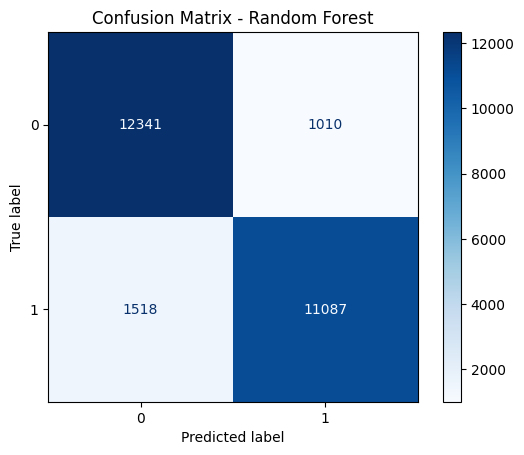

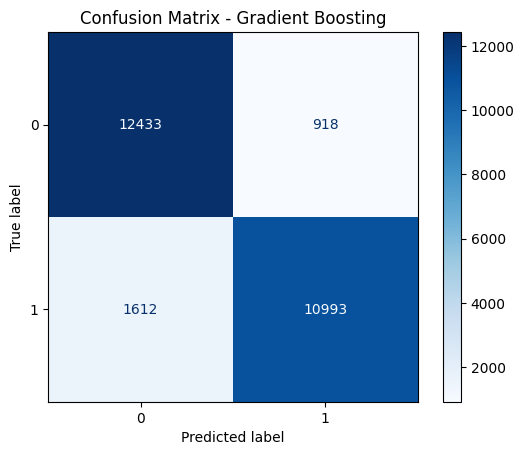

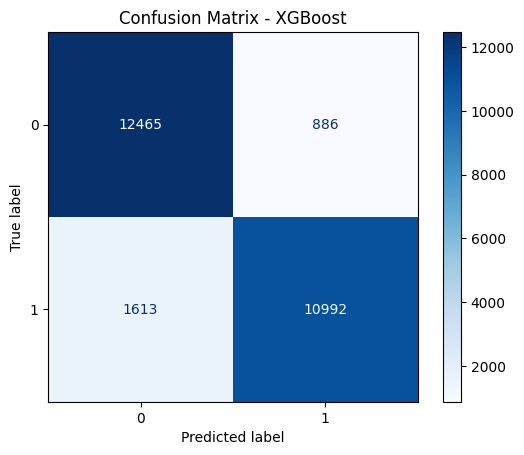

In [21]:
# conffusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, clf in model_terbaik_tersimpan.items():
    y_pred = clf.predict(X_test_scaled)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clf.classes_)
    disp.plot(cmap=plt.cm.Blues)
    plt.title(f'Confusion Matrix - {name}')
    plt.show()


Visualizing Feature Importance...


/tmp/ipykernel_4415/1625730594.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feature_importance, palette='viridis')


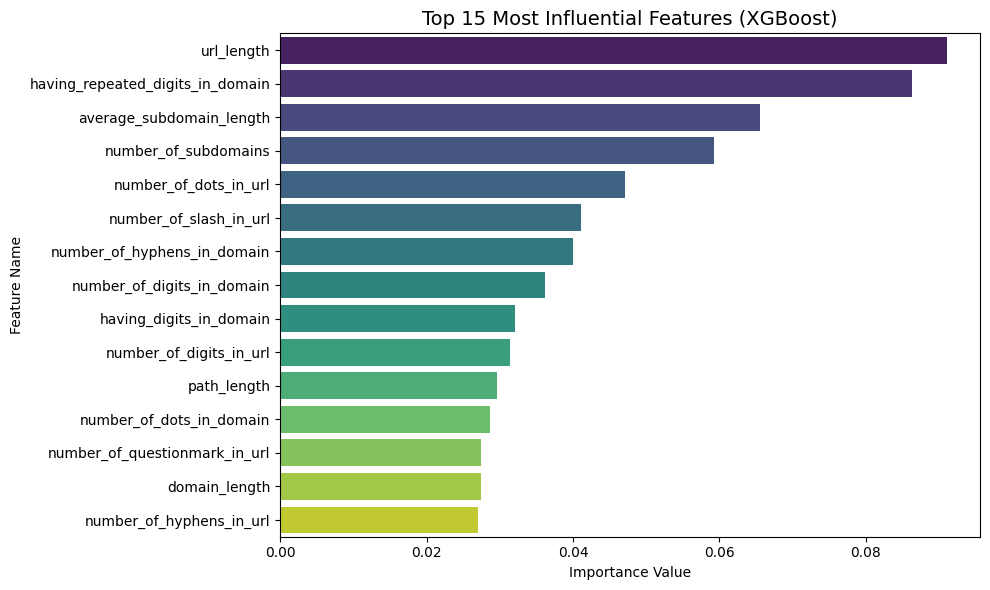

In [22]:
print("\nVisualizing Feature Importance...")
xgb_best_model = model_terbaik_tersimpan.get('XGBoost', None)

if xgb_best_model is None:
    print("No XGBoost model found in model_terbaik_tersimpan.")
else:
    if hasattr(xgb_best_model, 'feature_importances_') and getattr(xgb_best_model, 'feature_importances_') is not None:
        fi = xgb_best_model.feature_importances_
        if 'X_train' in globals() and hasattr(X_train, 'columns'):
            names = list(X_train.columns)
        elif 'X' in globals() and hasattr(X, 'columns'):
            names = list(X.columns)
        else:
            names = [f'feature_{i}' for i in range(len(fi))]
        names = names[:len(fi)]
        feature_importance = pd.DataFrame({'Feature': names, 'Importance': fi}).sort_values(by='Importance', ascending=False).head(15)
    else:
        try:
            score = xgb_best_model.get_booster().get_score(importance_type='weight')
            if not score:
                raise ValueError
            df_score = pd.DataFrame(list(score.items()), columns=['Feature', 'Importance'])
            if ('X_train' in globals() and hasattr(X_train, 'columns')) or ('X' in globals() and hasattr(X, 'columns')):
                cols = list(X_train.columns) if 'X_train' in globals() and hasattr(X_train, 'columns') else list(X.columns)
                df_score['Feature'] = df_score['Feature'].str.replace('f', '').astype(int).map(lambda i: cols[i] if i < len(cols) else f'f{i}')
            feature_importance = df_score.sort_values(by='Importance', ascending=False).head(15)
        except Exception:
            print("The model does not provide usable feature_importances_ or booster score.")
            feature_importance = None

    if feature_importance is not None and not feature_importance.empty:
        plt.figure(figsize=(10, 6))
        sns.barplot(x='Importance', y='Feature', data=feature_importance, palette='viridis')
        plt.title('Top 15 Most Influential Features (XGBoost)', fontsize=14)
        plt.xlabel('Importance Value')
        plt.ylabel('Feature Name')
        plt.tight_layout()
        plt.show()

In [ ]:
# confusion matrix untuk stacking
cm_stack = confusion_matrix(y_test, y_pred_stack)
disp_stack = ConfusionMatrixDisplay(confusion_matrix=cm_stack, display_labels=stacking_clf.classes_)
disp_stack.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix - Stacking Classifier')
plt.show()

    6.2 Deep Learning Models Evaluation & Comparison

        6.2.1 Tabular Neural Network Evaluation & Comparison

In [ ]:
print("Tabnet Evaluation Results:")
print(classification_report(y_val_np, y_pred_tabnet))

In [ ]:
#confusion matrix tabnet
cm_tabnet = confusion_matrix(y_val_np, y_pred_tabnet)
disp_tabnet = ConfusionMatrixDisplay(confusion_matrix=cm_tabnet, display_labels=clf_tabnet.classes_)
disp_tabnet.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix - TabNet')
plt.show() 

        6.2.2 Sequential Dense Layer Network Evaluation & Comparison

In [ ]:
y_val_pred_prob = model.predict(X_test_dl_final)
y_val_pred_keras = (y_val_pred_prob > 0.5).astype(int)
print(classification_report(y_dl_test, y_val_pred_keras, target_names=['Aman (0)', 'Phishing (1)']))

In [ ]:
# confusion matrix sequential dense layer keras
cm_keras = confusion_matrix(y_dl_test, y_val_pred_keras)
disp_keras = ConfusionMatrixDisplay(confusion_matrix=cm_keras, display_labels=['Aman (0)', 'Phishing (1)'])
disp_keras.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix - Sequential Dense Layer (Keras)')
plt.show()

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(ytta.history['accuracy'], label='Train Accuracy')
plt.plot(ytta.history['val_accuracy'], label='Validation Accuracy')
plt.title('Grafik Akurasi Model')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(ytta.history['loss'], label='Train Loss')
plt.plot(ytta.history['val_loss'], label='Validation Loss')
plt.title('Grafik Loss Model')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()

***

7. Final Model Selection & Submission

After evaluating and comparing all trained models, we selected XGBoost as our final submission. It delivered the best performance in terms of accuracy, F1-score, and recall, while also offering more efficient runtime than the other models. We then used XGBoost to predict labels on the test dataset and prepared the submission file following the FITCOMP 2026 formatting guidelines. Finally, we uploaded the submission to the competition platform for final evaluation.